In [47]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


df = pd.read_csv("/home/amir/Downloads/data_set/NASA_JPL_Dataset.csv")
df.head()
y = df["rms"].max()
a = df.describe()["rms"]
rms_avg = a["mean"]
print(rms_avg)
rms_std = a["std"]
print(rms_std)

treshhold = rms_avg + 2 * rms_std
print(treshhold)

cleaner_version = df[df["rms"] < treshhold]


0.5607640924613136
0.09878578641513272
0.7583356652915791


In [81]:

cleaner_version.describe()

temp = cleaner_version.describe()

diameter_sigma_column = temp["diameter_sigma"]
diameter_sigma_std = diameter_sigma_column["std"]
diameter_sigma_avg = diameter_sigma_column["mean"]

print(diameter_sigma_avg)
print(diameter_sigma_std)

diameter_treshhold =2 * diameter_sigma_std + diameter_sigma_avg

(cleaner_version["diameter_sigma"] > diameter_treshhold).sum()

super_cleaner_version = cleaner_version[cleaner_version["diameter_sigma"] < diameter_treshhold]

print(super_cleaner_version.shape)
print(df.shape)




0.4560478451565165
0.2122228078913105
(875842, 30)
(921425, 30)


In [50]:
pd.set_option('display.max_columns', None)  
pd.set_option('display.width', None)        

In [ ]:
input = super_cleaner_version.drop(columns=["diameter"])
output = super_cleaner_version["diameter"]

output


0          9.300
1         11.077
2         11.036
3          9.822
4         10.456
           ...  
921420     1.297
921421     1.111
921422     0.286
921423     1.417
921424     1.315
Name: diameter, Length: 908117, dtype: float64

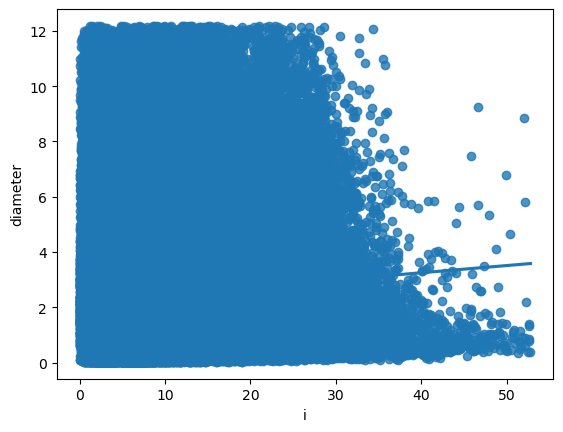

In [ ]:
sns.regplot(data = super_cleaner_version , x= "i" , y = "diameter")
plt.show()


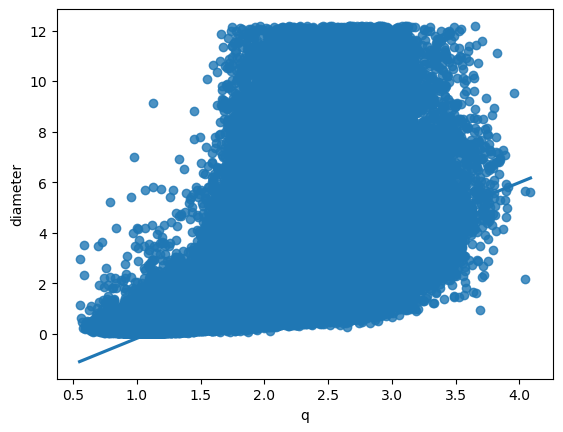

In [ ]:
sns.regplot(data = super_cleaner_version , x= "q" , y = "diameter")
plt.show()

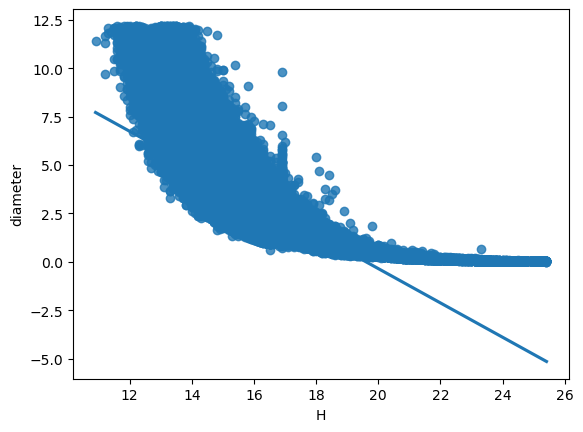

In [82]:
sns.regplot(data = super_cleaner_version , x= "H" , y = "diameter")
plt.show()

In [83]:
cleaner_version.columns

Index(['full_name', 'neo', 'pha', 'class', 'H', 'e', 'a', 'q', 'i', 'om', 'w',
       'ma', 'ad', 'n', 'per_y', 'moid', 'sigma_e', 'sigma_a', 'sigma_q',
       'sigma_i', 'sigma_om', 'sigma_w', 'sigma_ma', 'sigma_ad', 'sigma_n',
       'sigma_per', 'diameter_sigma', 'rms', 'albedo', 'diameter'],
      dtype='object')

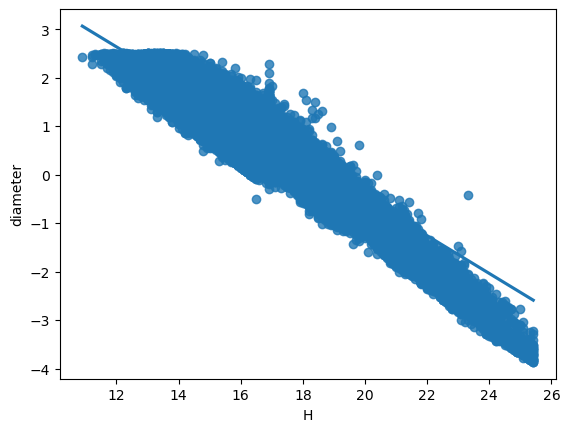

In [88]:
sns.regplot(data = super_cleaner_version , x=super_cleaner_version["H"] , y = np.log(super_cleaner_version["diameter"]))
plt.show()

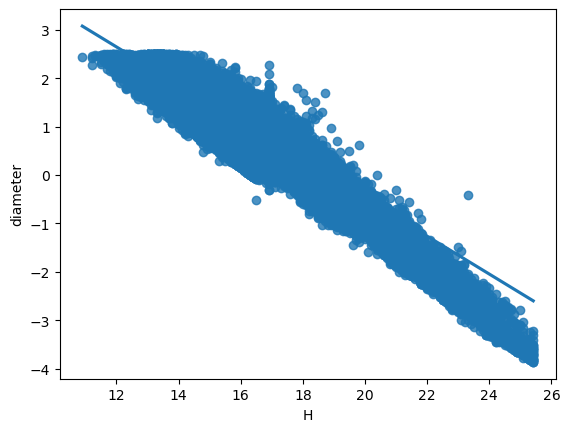

In [89]:
sns.regplot(data = df , x=df["H"] , y = np.log(df["diameter"]))
plt.show()